# Lab — EDA Bivariate Analysis: Amazon UK Product Insights (Part II)

**Objective:** Explore relationships between product categories, best-seller status, prices, and ratings on Amazon UK to support pricing and merchandising decisions.

**Dataset:** [Amazon UK Product Price Prediction](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/) (`amz_uk_price_prediction_dataset.csv`)

**Columns used:** `category`, `isBestSeller`, `price`, `stars`, `reviews`, `boughtInLastMonth`


In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Place the CSV in this folder after downloading from Kaggle
import os
import pandas as pd

CSV_PATH = "amz_uk_price_prediction_dataset.csv"


df = pd.read_csv(CSV_PATH)
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()


Shape: 2,443,651 rows × 9 columns


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.info()
print("\nMissing values:")
print(df.isnull().sum())


<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB

Missing values:
uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64


---
## Part 1: Analyzing Best-Seller Trends Across Product Categories

**Business question:** Is best-seller status evenly distributed across categories, or do some categories dominate Amazon's best-seller badges?


### 1. Crosstab analysis

We cross-tabulate `category` and `isBestSeller`, then compute the **proportion of best-sellers within each category** (row-wise normalization).


In [5]:
crosstab_counts = pd.crosstab(df["category"], df["isBestSeller"])
crosstab_prop = pd.crosstab(df["category"], df["isBestSeller"], normalize="index")

print("Counts (sample — top 5 categories by listings):")
print(crosstab_counts.loc[df["category"].value_counts().head(5).index])

print("\nProportion of best-sellers per category (top 15):")
best_seller_rate = crosstab_prop[True].sort_values(ascending=False)
print(best_seller_rate.head(15).to_frame("best_seller_rate"))


Counts (sample — top 5 categories by listings):
isBestSeller                             False  True 
category                                             
Sports & Outdoors                       835935    330
Beauty                                   19010    302
Handmade Clothing, Shoes & Accessories   19215     14
Bath & Body                              19059     33
Birthday Gifts                           18943     35

Proportion of best-sellers per category (top 15):
                                best_seller_rate
category                                        
Grocery                                 0.058135
Smart Home Security & Lighting          0.057692
Health & Personal Care                  0.057686
Mobile Phone Accessories                0.042471
Power & Hand Tools                      0.035339
Billiard, Snooker & Pool                0.032129
Pet Supplies                            0.030200
Home Brewing & Wine Making              0.028455
Wind Instruments                 

**Insight:** Best-seller status is **not uniform** across categories. Categories such as **Grocery**, **Smart Home Security & Lighting**, and **Health & Personal Care** show the highest share of listings flagged as best-sellers (~5–6%), while many categories sit closer to ~2–3%. High-volume categories (e.g. Sports & Outdoors) are not necessarily the ones with the highest best-seller *rate* — frequency and prevalence are different questions.


### 2. Statistical tests

- **Chi-square test of independence** — tests whether category and best-seller status are independent.
- **Cramér's V** — measures association strength (0 = none, 1 = strong) on categorical data.


In [6]:
chi2, p_value, dof, expected = chi2_contingency(crosstab_counts)
n = crosstab_counts.to_numpy().sum()
min_dim = min(crosstab_counts.shape[0] - 1, crosstab_counts.shape[1] - 1)
cramers_v = np.sqrt(chi2 / (n * min_dim))

print(f"Chi-square statistic: {chi2:,.2f}")
print(f"Degrees of freedom:   {dof:,}")
print(f"p-value:              {p_value:.2e}")
print(f"Cramér's V:           {cramers_v:.4f}")

if p_value < 0.05:
    print("\nConclusion: Reject H0 — best-seller distribution is NOT independent of category.")
else:
    print("\nConclusion: Fail to reject H0 — no evidence of association.")


Chi-square statistic: 36,540.20
Degrees of freedom:   295
p-value:              0.00e+00
Cramér's V:           0.1223

Conclusion: Reject H0 — best-seller distribution is NOT independent of category.


**Insight:** A very small p-value indicates a **statistically significant** relationship between category and best-seller status. Cramér's V (~0.12) suggests a **weak-to-moderate** association in practice: category matters, but best-seller status is still driven by many other factors (reviews, price, seasonality).


### 3. Visualization — stacked bar chart


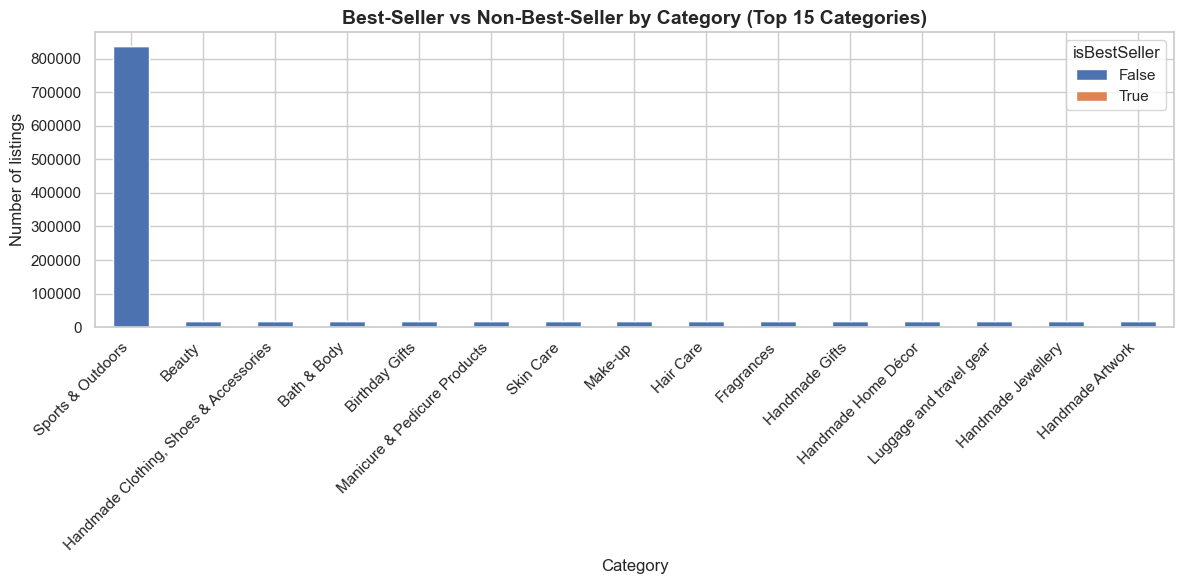

In [7]:
# Top 15 categories by listing count for readability
top_cats_bs = df["category"].value_counts().head(15).index
plot_df = df[df["category"].isin(top_cats_bs)]

ct_plot = pd.crosstab(plot_df["category"], plot_df["isBestSeller"])
ct_plot = ct_plot.loc[top_cats_bs]  # order by volume

ax = ct_plot.plot(kind="bar", stacked=True, figsize=(12, 6), color=["#4C72B0", "#DD8452"])
ax.set_title("Best-Seller vs Non-Best-Seller by Category (Top 15 Categories)", fontsize=14, fontweight="bold")
ax.set_xlabel("Category")
ax.set_ylabel("Number of listings")
plt.xticks(rotation=45, ha="right")
plt.legend(title="isBestSeller", labels=["False", "True"])
plt.tight_layout()
plt.show()


---
## Part 2: Product Prices and Ratings Across Categories

**Business question:** How do prices and customer ratings vary by category after removing extreme price outliers?


### 0. Remove price outliers (IQR method)

Prices outside \[Q1 − 1.5×IQR, Q3 + 1.5×IQR\] are treated as outliers and removed. All analyses in Part 2 and Part 3 use this cleaned dataset unless noted.


In [8]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print(f"Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}")
print(f"Valid price range: [{lower:.2f}, {upper:.2f}]")

df_clean = df[(df["price"] >= lower) & (df["price"] <= upper)].copy()
removed = len(df) - len(df_clean)
print(f"\nRemoved {removed:,} outliers ({removed/len(df)*100:.1f}%)")
print(f"Clean dataset shape: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns")


Q1=9.99, Q3=45.99, IQR=36.00
Valid price range: [-44.01, 99.99]

Removed 327,688 outliers (13.4%)
Clean dataset shape: 2,115,963 rows × 9 columns


### 1. Violin plots — price distribution (top 20 categories by count)


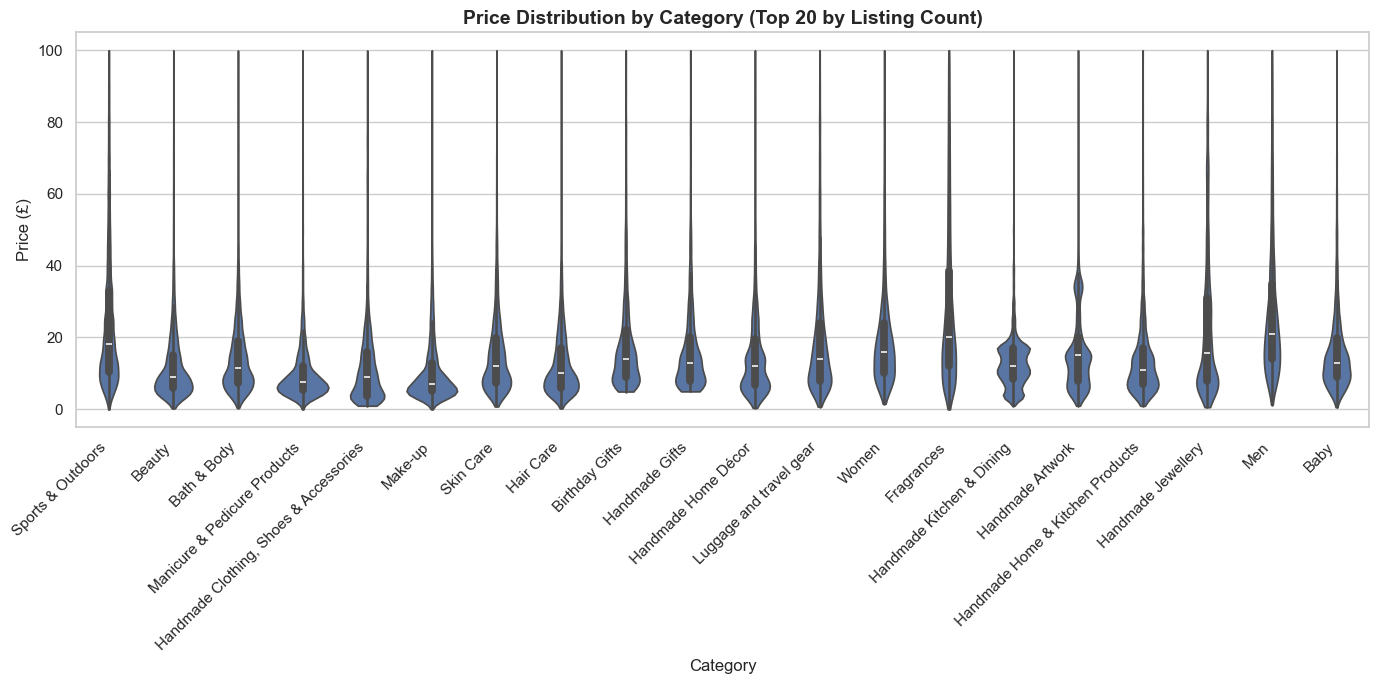

Category with highest median price (all categories):
category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64


In [9]:
top20_cats = df_clean["category"].value_counts().head(20).index
df_top20 = df_clean[df_clean["category"].isin(top20_cats)]

plt.figure(figsize=(14, 7))
sns.violinplot(data=df_top20, x="category", y="price", order=top20_cats, cut=0)
plt.title("Price Distribution by Category (Top 20 by Listing Count)", fontsize=14, fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Price (£)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# All categories — highest median price
median_price_all = df_clean.groupby("category")["price"].median().sort_values(ascending=False)
print("Category with highest median price (all categories):")
print(median_price_all.head(5))


**Insight (violin, top 20):** Price spreads differ visibly by category — electronics and specialty niches show wider bodies and longer tails than mass-market categories. **Across all categories**, **Desktop PCs** has the highest **median** price (~£74), reflecting a structurally expensive segment.


### 2. Bar chart — average price (top 10 categories by count)


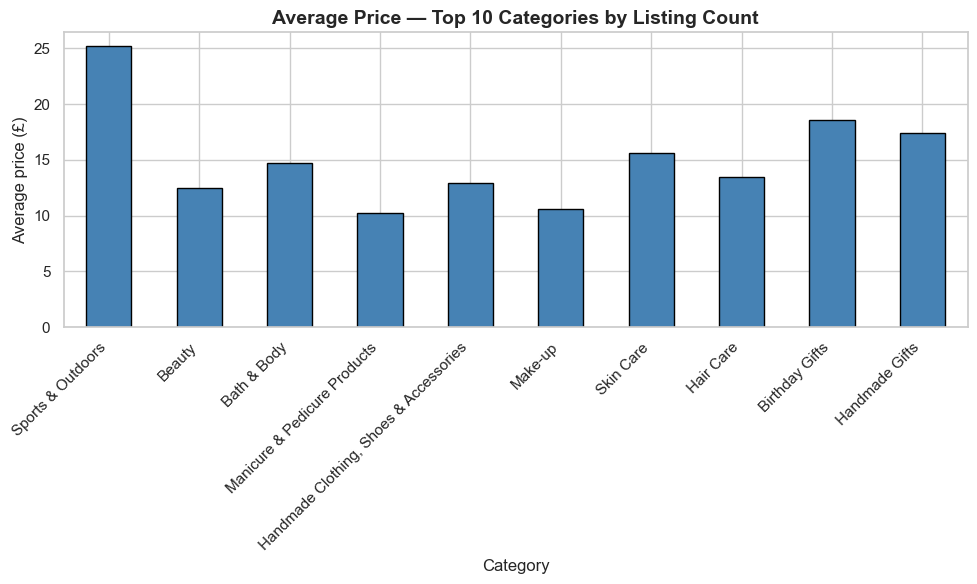

Category with highest average price (all categories):
category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64


In [10]:
top10_cats = df_clean["category"].value_counts().head(10).index
avg_price_top10 = (
    df_clean[df_clean["category"].isin(top10_cats)]
    .groupby("category")["price"]
    .mean()
    .loc[top10_cats]
)

plt.figure(figsize=(10, 6))
avg_price_top10.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Average Price — Top 10 Categories by Listing Count", fontsize=14, fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Average price (£)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

mean_price_all = df_clean.groupby("category")["price"].mean().sort_values(ascending=False)
print("Category with highest average price (all categories):")
print(mean_price_all.head(5))


**Insight:** Among high-volume categories, average prices cluster in a moderate band. **Motherboards** has the highest **mean** price across all categories (~£69), while the top-10-by-volume chart highlights differences among Amazon's largest aisles — useful for category-level pricing benchmarks.


### 3. Box plots — ratings (`stars`) by category (top 10 by count)


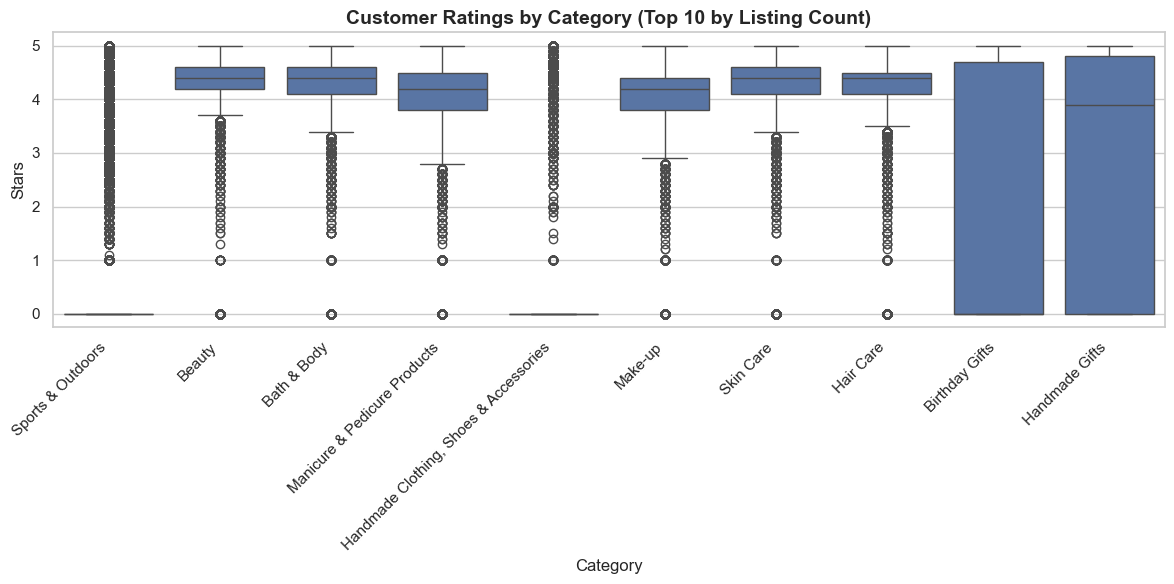

Category with highest median rating (all categories):
category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64


In [11]:
top10_rating = df_clean["category"].value_counts().head(10).index
df_top10_rating = df_clean[df_clean["category"].isin(top10_rating)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top10_rating, x="category", y="stars", order=top10_rating)
plt.title("Customer Ratings by Category (Top 10 by Listing Count)", fontsize=14, fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Stars")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

median_rating_all = df_clean.groupby("category")["stars"].median().sort_values(ascending=False)
print("Category with highest median rating (all categories):")
print(median_rating_all.head(5))


**Insight:** Ratings are **compressed near 4.3–4.7** for most large categories — customers rarely see wide rating dispersion at the category level. **Computer Memory** shows the highest **median** rating (~4.7) across all categories. Box plots for top categories confirm generally high satisfaction with modest between-category differences.


---
## Part 3: Product Prices vs Ratings

**Business question:** Do more expensive products earn higher customer ratings?


### 1. Correlation coefficient


In [16]:
pearson_r = df_clean["price"].corr(df_clean["stars"])
spearman_r = df_clean["price"].corr(df_clean["stars"], method="spearman")

print(f"Pearson correlation (price vs stars):  {pearson_r:.4f}")
print(f"Spearman correlation (price vs stars): {spearman_r:.4f}")


Pearson correlation (price vs stars):  -0.0777
Spearman correlation (price vs stars): -0.0668


**Insight:** The Pearson correlation is **weak and negative** (≈ −0.08): higher price is **not** associated with higher ratings. Paying more does not guarantee better perceived quality on Amazon UK. Any relationship is negligible for practical pricing decisions.


### 2. Visualizations


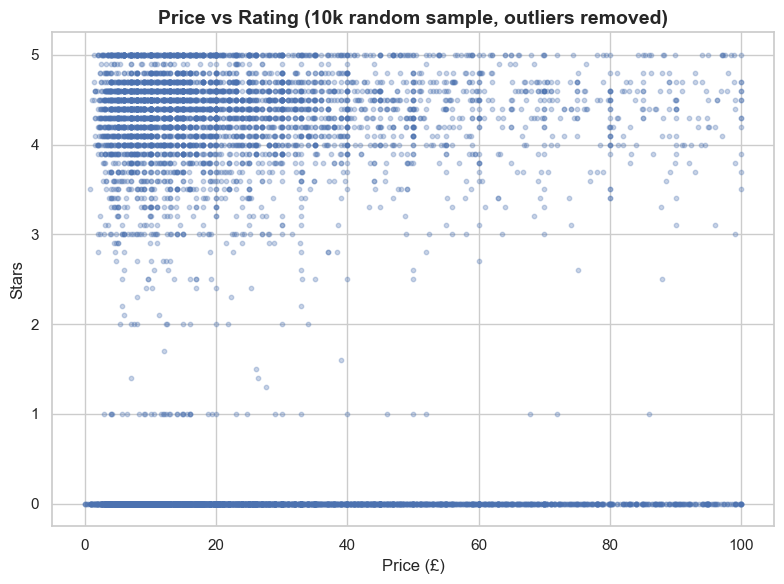

In [17]:
# Scatter (sample for performance)
sample = df_clean.sample(n=min(10000, len(df_clean)), random_state=42)

plt.figure(figsize=(8, 6))
plt.scatter(sample["price"], sample["stars"], alpha=0.3, s=10)
plt.xlabel("Price (£)")
plt.ylabel("Stars")
plt.title("Price vs Rating (10k random sample, outliers removed)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


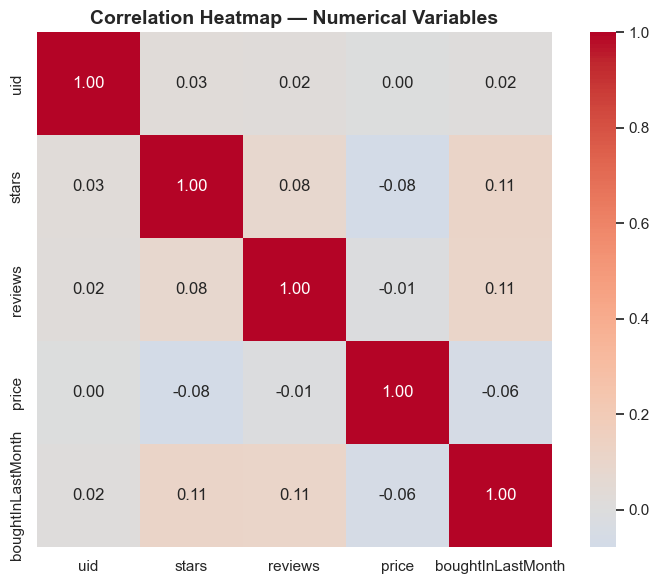

In [18]:
# Correlation heatmap — numerical columns
num_cols = df_clean.select_dtypes(include=[np.number]).columns
corr_matrix = df_clean[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap — Numerical Variables", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


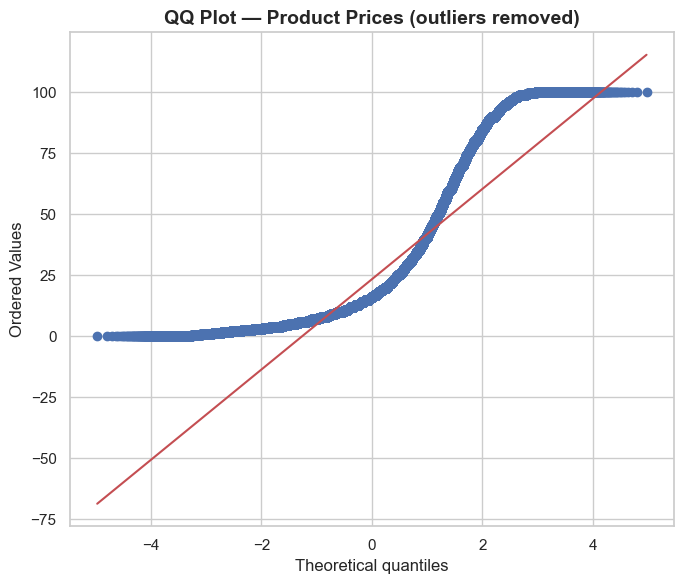

In [19]:
# QQ plot — are prices normally distributed?
plt.figure(figsize=(7, 6))
stats.probplot(df_clean["price"], dist="norm", plot=plt)
plt.title("QQ Plot — Product Prices (outliers removed)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


**Visualization insights:**

- **Scatter plot:** Points form a dense cloud with no clear upward trend; ratings stay high across price levels.
- **Heatmap:** `price` and `stars` show weak correlation; `reviews` and `boughtInLastMonth` may correlate more with visibility than with price.
- **QQ plot:** Prices **deviate strongly from a normal distribution** (heavy right skew even after IQR filtering) — mean-based summaries should be interpreted alongside medians.


---
## Business Report Summary

| Area | Key finding | Recommendation |
|------|-------------|----------------|
| Best-seller × category | Significant association (χ² test); weak Cramér's V | Prioritize best-seller campaigns in Grocery, Smart Home, and Health categories |
| Pricing by category | Median/mean vary widely; Desktop PCs & Motherboards at premium end | Use **category-specific** price benchmarks, not marketplace averages |
| Ratings by category | Ratings clustered high; small between-category gaps | Compete on reviews volume and recency, not only star level |
| Price vs rating | ~no linear relationship | Do not assume premium pricing improves ratings; validate with A/B tests |

---
## Bonus: Analysis **without** removing price outliers


In [20]:
pearson_full = df["price"].corr(df["stars"])
print(f"Pearson (full data, with outliers): {pearson_full:.4f}")
print(f"Pearson (IQR-cleaned data):         {pearson_r:.4f}")

Q1_f, Q3_f = df["price"].quantile([0.25, 0.75])
print(f"\nFull data — mean price: £{df['price'].mean():.2f}, median: £{df['price'].median():.2f}")
print(f"Clean data — mean price: £{df_clean['price'].mean():.2f}, median: £{df_clean['price'].median():.2f}")


Pearson (full data, with outliers): -0.1249
Pearson (IQR-cleaned data):         -0.0777

Full data — mean price: £89.24, median: £19.09
Clean data — mean price: £23.41, median: £15.99


**Bonus insight:** With outliers included, the price–rating correlation is **more negative** (≈ −0.12 vs ≈ −0.08) because extreme high prices pull the relationship without improving ratings. Outliers also inflate the **mean** price dramatically while the **median** stays more stable — another reason to report medians and use IQR filtering for category pricing analysis.
